In [1]:
import numpy as np
import pandas as pd

gene_level_local_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_local_overlap_allpair.csv')
gene_level_global_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_global_overlap_allpair.csv')
local_metrics = np.sum(gene_level_local_metrics.set_index('gene')>2.5, axis=0)/gene_level_local_metrics.shape[0]
global_metrics = np.sum(gene_level_global_metrics.set_index('gene')>2.5, axis=0)/gene_level_global_metrics.shape[0]
local_metrics = local_metrics.reset_index()
global_metrics = global_metrics.reset_index()
prior_z_score = (gene_level_local_metrics.set_index('gene').mean(axis=1)+gene_level_global_metrics.set_index('gene').mean(axis=1))/2
prior_intrinsic_scores = (gene_level_local_metrics.set_index('gene')+gene_level_global_metrics.set_index('gene'))/2

In [2]:
import pandas as pd
gene_level_local_metrics = {}
gene_level_global_metrics = {}
analysis_targets = ['K562_GWPS','K562_Essential','RPE1_Essential','HepG2_Essential','Jurkat_Essential', 'RPE1_Southard']
for analysis_target in analysis_targets: 
    gene_level_local_metrics[analysis_target] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{analysis_target}_pertspace_gene_local_overlap_allpair.csv').set_index('gene')
    gene_level_global_metrics[analysis_target] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{analysis_target}_pertspace_gene_global_overlap_allpair.csv').set_index('gene')

import numpy as np

plot_df_local = []
plot_df_global = []
for analysis_target in analysis_targets: #,'RPE1_Southard']:
    local_metrics = np.sum(gene_level_local_metrics[analysis_target]>2.5, axis=0)/gene_level_local_metrics[analysis_target].shape[0]
    global_metrics = np.sum(gene_level_global_metrics[analysis_target]>2.5, axis=0)/gene_level_global_metrics[analysis_target].shape[0]
    plot_df_local.append(local_metrics)
    plot_df_global.append(global_metrics)

plot_df_local = pd.concat(plot_df_local, axis=1)
plot_df_local.columns=analysis_targets
plot_df_global = pd.concat(plot_df_global, axis=1)
plot_df_global.columns=analysis_targets

Text(0.5, 1.0, 'Mean and Stdev of cofunction agreement score, N=1625')

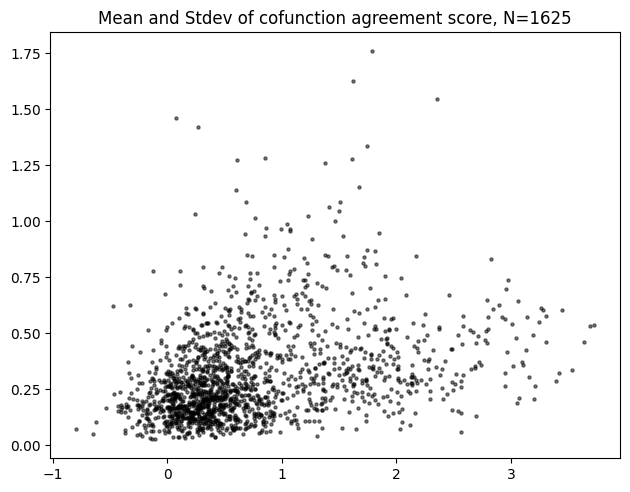

In [3]:
import matplotlib.pyplot as plt
for i, perturb_seq_name in enumerate(analysis_targets[1:-1]): 
    local_df = gene_level_local_metrics[perturb_seq_name].mean(axis=1)
    global_df = gene_level_global_metrics[perturb_seq_name].mean(axis=1)
    prior_pert_z_score = (global_df+local_df)/2
    current_joint_genes = list(set(prior_z_score.index).intersection(set(prior_pert_z_score.index)))
    if i == 0:
        all_perturbseq_joint_genes = current_joint_genes
    else:
        all_perturbseq_joint_genes = list(set(current_joint_genes).intersection(all_perturbseq_joint_genes))

prior_pert_z_scores = []

for i, perturb_seq_name in enumerate(analysis_targets[1:-1]): 
    local_df = gene_level_local_metrics[perturb_seq_name].mean(axis=1)
    global_df = gene_level_global_metrics[perturb_seq_name].mean(axis=1)
    prior_pert_z_score = (global_df+local_df)/2
    
    plot_prior_z = prior_z_score.loc[all_perturbseq_joint_genes]
    plot_prior_pert_z = prior_pert_z_score.loc[all_perturbseq_joint_genes]
    
    prior_pert_z_scores.append(plot_prior_pert_z)

plt.scatter(np.mean(prior_pert_z_scores, axis=0), np.std(prior_pert_z_scores, axis=0), s=5, alpha=0.5, color='black')
plt.tight_layout()
plt.title(f'Mean and Stdev of cofunction agreement score, N={len(prior_pert_z_scores[0])}')

Text(0.5, 0, 'Mean')

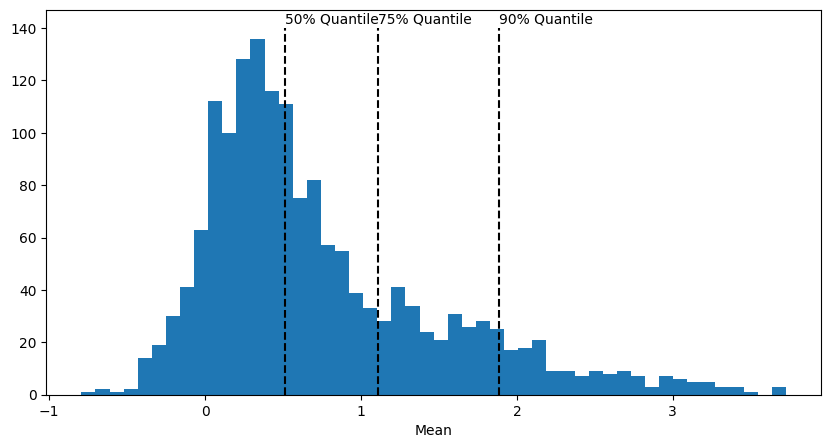

In [4]:
plt.figure(figsize=(10,5))
plt.hist(np.mean(prior_pert_z_scores, axis=0), bins=50)
plt.vlines(x = np.quantile(np.mean(prior_pert_z_scores, axis=0), 0.5), ymin=0, ymax=140, color='black', linestyle='--')
plt.text(x = np.quantile(np.mean(prior_pert_z_scores, axis=0), 0.5), y=142, s='50% Quantile')

plt.vlines(x = np.quantile(np.mean(prior_pert_z_scores, axis=0), 0.75), ymin=0, ymax=140, color='black', linestyle='--')
plt.text(x = np.quantile(np.mean(prior_pert_z_scores, axis=0), 0.75), y=142, s='75% Quantile')

plt.vlines(x = np.quantile(np.mean(prior_pert_z_scores, axis=0), 0.9), ymin=0, ymax=140, color='black', linestyle='--')
plt.text(x = np.quantile(np.mean(prior_pert_z_scores, axis=0), 0.9), y=142, s='90% Quantile')
plt.xlabel('Mean')
#plt.savefig('../figure_out/Fig.S3F_1.pdf')

Text(0.5, 0, 'Standard deviation')

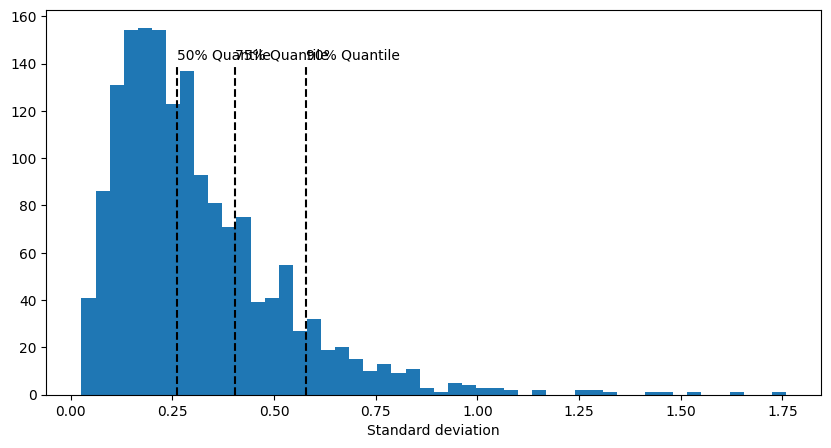

In [5]:
plt.figure(figsize=(10,5))
plt.hist(np.std(prior_pert_z_scores, axis=0), bins=50)
plt.vlines(x = np.quantile(np.std(prior_pert_z_scores, axis=0), 0.5), ymin=0, ymax=140, color='black', linestyle='--')
plt.text(x = np.quantile(np.std(prior_pert_z_scores, axis=0), 0.5), y=142, s='50% Quantile')

plt.vlines(x = np.quantile(np.std(prior_pert_z_scores, axis=0), 0.75), ymin=0, ymax=140, color='black', linestyle='--')
plt.text(x = np.quantile(np.std(prior_pert_z_scores, axis=0), 0.75), y=142, s='75% Quantile')

plt.vlines(x = np.quantile(np.std(prior_pert_z_scores, axis=0), 0.9), ymin=0, ymax=140, color='black', linestyle='--')
plt.text(x = np.quantile(np.std(prior_pert_z_scores, axis=0), 0.9), y=142, s='90% Quantile')
plt.xlabel('Standard deviation')
#plt.savefig('../figure_out/Fig.S3F_2.pdf')

In [6]:
plot_df = pd.DataFrame([np.mean(prior_pert_z_scores, axis=0), np.std(prior_pert_z_scores, axis=0)], index=['mean','stdev'], columns=all_perturbseq_joint_genes).T
universal_strong_genes = plot_df[plot_df['mean']>0.5][plot_df['stdev']<0.25].index.tolist()
universal_weak_genes = plot_df[plot_df['mean']<0.5][plot_df['stdev']<0.25].index.tolist()
specific_strong_genes = plot_df[plot_df['mean']<0.5][plot_df['stdev']>0.25].index.tolist()

/tmp/ipykernel_2716502/2171845395.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  universal_strong_genes = plot_df[plot_df['mean']>0.5][plot_df['stdev']<0.25].index.tolist()
/tmp/ipykernel_2716502/2171845395.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  universal_weak_genes = plot_df[plot_df['mean']<0.5][plot_df['stdev']<0.25].index.tolist()
/tmp/ipykernel_2716502/2171845395.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  specific_strong_genes = plot_df[plot_df['mean']<0.5][plot_df['stdev']>0.25].index.tolist()


GO_Biological_Process_2023__mRNA Splicing, Via Spliceosome (GO:0000398)
SNW1;MAGOH;SF3A1;TGS1;PUF60;PPIL1;YTHDC1;GEMIN7;DHX9;GEMIN6;WDR77;RNPC3;PRMT5;SRSF7;SRSF2;SDE2;PPIH;PABPC1;STRAP;HNRNPU
CORUM__Spliceosome (human)
WBP11;SNW1;MAGOH;SF3A1;PUF60;PPIL1;DHX9;PPIL2;NUDT21;ZNF207;TCERG1;PPIH;RNPS1;CD2BP2;CPSF6;DNAJC8
GO_Biological_Process_2023__ncRNA Processing (GO:0034470)
NOP56;RPS25;XRN2;TUT1
GO_Biological_Process_2023__protein-RNA Complex Assembly (GO:0022618)
TGS1;PUF60;YTHDC1;GEMIN7;DHX9;GEMIN6;WDR77;EIF3H;EIF5;PRMT5;NUDT21;EIF3J;STRAP;SHQ1
GO_Biological_Process_2023__Positive Regulation Of Cell Cycle Process (GO:0090068)
SASS6;SMC2;NCAPG2;NCAPH;STIL;NCAPH2;AURKA;SMC4;SMC6;XRCC3;PCID2;MAD2L1;PLK4;NCAPD3;DDX11


<Axes: title={'center': 'Top 5 NES Terms (FDR<0.1)'}, xlabel='NES'>

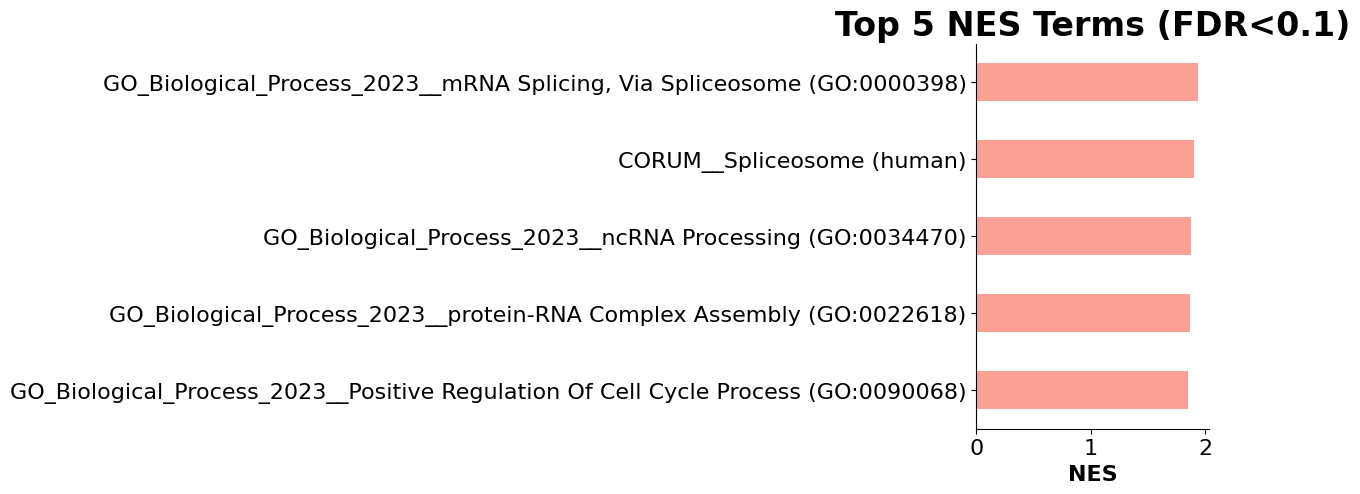

In [7]:
import gseapy as gp

plot_df = pd.DataFrame([np.mean(prior_pert_z_scores, axis=0), np.std(prior_pert_z_scores, axis=0)], index=['mean','stdev'], columns=all_perturbseq_joint_genes).T

res = gp.prerank(rnk=plot_df[plot_df['mean']<0.5]['stdev'], gene_sets=['CORUM','GO_Biological_Process_2023'], seed=42, min_size=10, max_size=500)
for i in range(5):
    print(res.res2d[res.res2d['FDR q-val']<0.1].Term[i])
    print(res.res2d[res.res2d['FDR q-val']<0.1].head()['Lead_genes'].iloc[i])
gp.barplot(res.res2d, figsize=(3,5), column='NES', cutoff=0.1, top_term=5, title='Top 5 NES Terms (FDR<0.1)')
#plt.savefig('../figure_out/Fig.S3G.pdf')

GO_Biological_Process_2023__mRNA Splicing, Via Spliceosome (GO:0000398)
SLU7;PRPF8;SF3B5;SF3B3;CWC22;SNRPD2;LSM4;MFAP1;CWC15;SF3B1;LSM7;U2AF1;DHX16;PLRG1;SART3;DHX8;CACTIN;SNIP1;DNAJC17;DDX20;GEMIN5;DHX15;DDX41;CLNS1A;SART1
GO_Biological_Process_2023__RNA Splicing, Via Transesterification Reactions With Bulged Adenosine As Nucleophile (GO:0000377)
SLU7;PRPF8;SF3B5;SF3B3;CWC22;SNRPD2;LSM4;MFAP1;CWC15;SF3B1;LSM7;U2AF1;DHX16;PLRG1;SART3;DHX8;CACTIN;SNIP1;GEMIN5;DHX15;DDX41;SART1
GO_Biological_Process_2023__mRNA Processing (GO:0006397)
SLU7;PRPF8;SF3B5;SF3B3;CWC22;SNRPD2;LSM4;MFAP1;CWC15;SF3B1;LSM7;U2AF1;DHX16;PLRG1;SART3;DHX8;CACTIN;SNIP1;GEMIN5;DHX15;DDX41;SART1
GO_Biological_Process_2023__Peptide Biosynthetic Process (GO:0043043)
RPL6;RPL38;RPL8;RPL13;MRPS18A;RPL15;MRPL18
CORUM__Spliceosome (human)
SLU7;PRPF8;SF3B3;CWC22;SNRPD2;LSM4;MFAP1;CWC15;SF3B1;LSM7;U2AF1;DHX16;PLRG1;DHX8;DHX15;DDX41;SART1


<Axes: title={'center': 'Top 5 NES Terms (FDR<0.1)'}, xlabel='NES'>

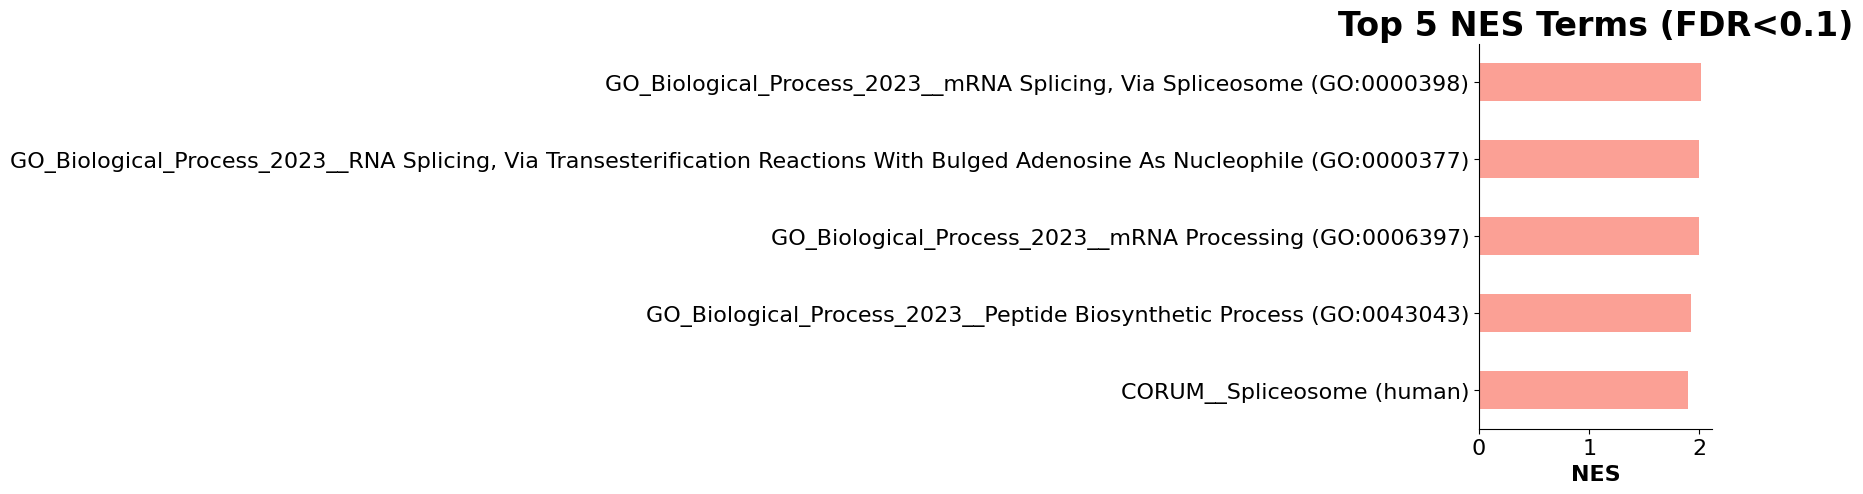

In [8]:
import gseapy as gp

plot_df = pd.DataFrame([np.mean(prior_pert_z_scores, axis=0), np.std(prior_pert_z_scores, axis=0)], index=['mean','stdev'], columns=all_perturbseq_joint_genes).T

res = gp.prerank(rnk=plot_df[plot_df['stdev']<0.25]['mean'], gene_sets=['CORUM','GO_Biological_Process_2023'], seed=42, min_size=10, max_size=500)
for i in range(5):
    print(res.res2d[res.res2d['FDR q-val']<0.1].Term[i])
    print(res.res2d[res.res2d['FDR q-val']<0.1].head()['Lead_genes'].iloc[i])
gp.barplot(res.res2d, figsize=(3,5), column='NES', cutoff=0.1, top_term=5, title='Top 5 NES Terms (FDR<0.1)')
#plt.savefig('../figure_out/Fig.S3H.pdf')

In [9]:
import seaborn as sns
import gseapy as gp
library = gp.get_library(name='CORUM', organism='Human')
spliceosome_genes = list(set(library['Spliceosome (human)']).intersection(all_perturbseq_joint_genes))
cellline_specific_spliceosome_genes = "WBP11;SNW1;MAGOH;SF3A1;PUF60;PPIL1;DHX9;PPIL2;NUDT21;ZNF207;TCERG1;PPIH;RNPS1;CD2BP2;CPSF6;DNAJC8"
cellline_specific_spliceosome_genes = cellline_specific_spliceosome_genes.split(';')

universal_spliceosome_genes = "SLU7;PRPF8;SF3B3;CWC22;SNRPD2;LSM4;MFAP1;CWC15;SF3B1;LSM7;U2AF1;DHX16;PLRG1;DHX8;DHX15;DDX41;SART1"
universal_spliceosome_genes = universal_spliceosome_genes.split(';')
remainder_spliceosome_genes = list(set(spliceosome_genes).difference(set(cellline_specific_spliceosome_genes)).union(set(universal_spliceosome_genes)))

plot_df = pd.DataFrame(prior_pert_z_scores, columns = all_perturbseq_joint_genes, index = analysis_targets[1:-1])

Text(0.5, 1.0, 'Correlation of cofunction agreement score (N=86)')

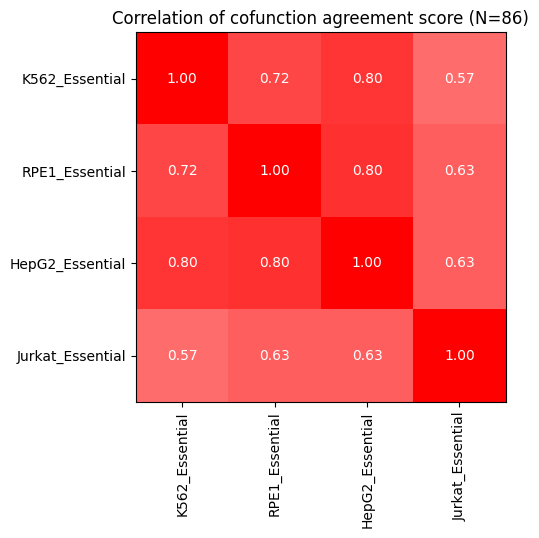

In [10]:
fig, ax = plt.subplots()
ax.imshow(np.corrcoef(plot_df[spliceosome_genes]), cmap='bwr', vmin=-1, vmax=1)
for i in range(4):
    for j in range(4):
        text = ax.text(j, i, f'{np.corrcoef(plot_df[spliceosome_genes])[i, j]:.2f}', ha="center", va="center", color="w")
ax.set_xticks(ticks=range(4), labels=analysis_targets[1:-1], rotation=90)
ax.set_yticks(ticks=range(4), labels=analysis_targets[1:-1])
ax.set_title(f'Correlation of cofunction agreement score (N={len(spliceosome_genes)})')
#plt.savefig('../figure_out/Fig.4G_all_spliceosome.pdf')

Text(0.5, 1.0, 'Correlation of cofunction agreement score (N=17)')

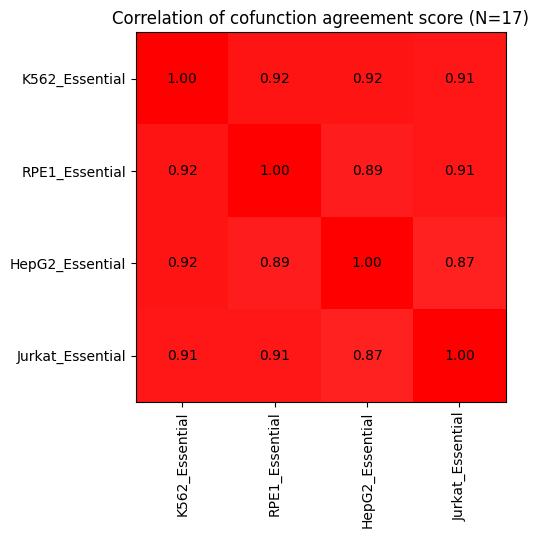

In [11]:
fig, ax = plt.subplots()
ax.imshow(np.corrcoef(plot_df[universal_spliceosome_genes]), cmap='bwr', vmin=-1, vmax=1)
for i in range(4):
    for j in range(4):
        text = ax.text(j, i, f'{np.corrcoef(plot_df[universal_spliceosome_genes])[i, j]:.2f}', ha="center", va="center", color="black")
ax.set_xticks(ticks=range(4), labels=analysis_targets[1:-1], rotation=90)
ax.set_yticks(ticks=range(4), labels=analysis_targets[1:-1])
ax.set_title(f'Correlation of cofunction agreement score (N={len(universal_spliceosome_genes)})')
#plt.savefig('../figure_out/Fig.4G_context_stable.pdf')

Text(0.5, 1.0, 'Correlation of cofunction agreement score (N=16)')

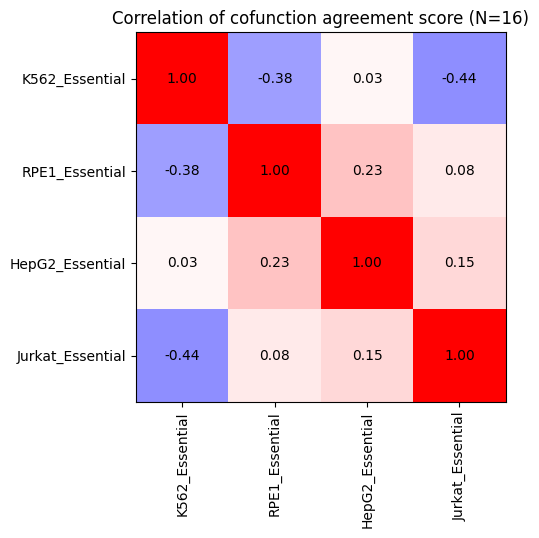

In [12]:
fig, ax = plt.subplots()
ax.imshow(np.corrcoef(plot_df[cellline_specific_spliceosome_genes]), cmap='bwr', vmin=-1, vmax=1)
for i in range(4):
    for j in range(4):
        text = ax.text(j, i, f'{np.corrcoef(plot_df[cellline_specific_spliceosome_genes])[i, j]:.2f}', ha="center", va="center", color="black")
ax.set_xticks(ticks=range(4), labels=analysis_targets[1:-1], rotation=90)
ax.set_yticks(ticks=range(4), labels=analysis_targets[1:-1])
ax.set_title(f'Correlation of cofunction agreement score (N={len(cellline_specific_spliceosome_genes)})')
#plt.savefig('../figure_out/Fig.4G_context_specific.pdf')

### Fig. 4F

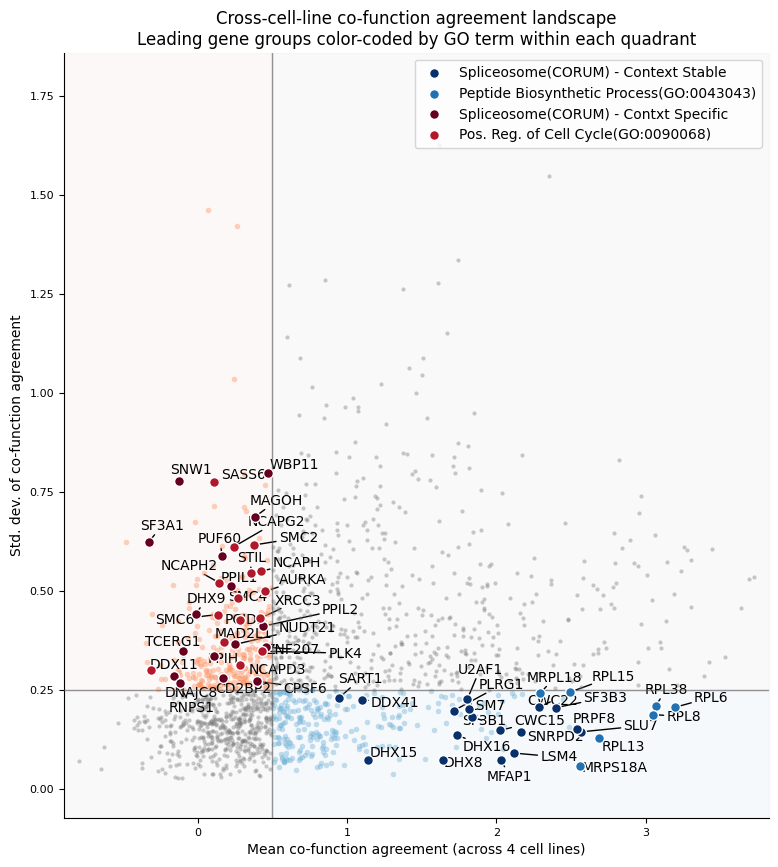

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from adjustText import adjust_text

warnings.filterwarnings("ignore")

texts=[]

# Quandrants color
C_US_BG  = "#6BAED6"
C_UW_BG  = "#777777"
C_SS_BG  = "#FC8D59"
C_Q4_BG  = "#777777"

SHADES = {
    # Context-stable
    "US_1": {"color": "#08306B", "label": "Spliceosome(CORUM) - Context Stable",
             "genes": universal_spliceosome_genes},
    "US_2": {"color": "#2171B5", "label": "Peptide Biosynthetic Process(GO:0043043)",
             "genes": ["RPL6","RPL38","RPL8","RPL13","MRPS18A","RPL15","MRPL18"]},

    # Context-specific
    "SS_1": {"color": "#67001F", "label": "Spliceosome(CORUM) - Contxt Specific",
             "genes": cellline_specific_spliceosome_genes},
    "SS_2": {"color": "#B2182B", "label": "Pos. Reg. of Cell Cycle(GO:0090068)",
             "genes": ["SASS6","SMC2","NCAPG2","NCAPH","STIL","NCAPH2","AURKA","SMC4","SMC6","XRCC3","PCID2","MAD2L1","PLK4","NCAPD3","DDX11"]}
}

MEAN_CUT, STD_CUT = 0.5, 0.25

ms = pd.DataFrame([np.mean(prior_pert_z_scores, axis=0), np.std(prior_pert_z_scores, axis=0)], index=['mean','stdev'], columns=all_perturbseq_joint_genes).T


def assign_quad(r):
    if   r["mean"] >= MEAN_CUT and r["stdev"] < STD_CUT:  return "US"
    elif r["mean"] <  MEAN_CUT and r["stdev"] < STD_CUT:  return "UW"
    elif r["mean"] <  MEAN_CUT and r["stdev"] >= STD_CUT: return "SS"
    else:                                                   return "Q4"

ms["quad"] = ms.apply(assign_quad, axis=1)
counts = ms["quad"].value_counts()

gene_shade = {}
for key, info in SHADES.items():
    for g in info["genes"]:
        if g in ms.index:
            gene_shade[g] = key

fig = plt.figure(figsize=(13, 8.5))

gs = fig.add_gridspec(
    3, 4,
    width_ratios=[1.0, 0.2, 0.2, 0.2],
    left=0.05, right=0.95,
    top=0.95, bottom=0.05,
    wspace=0.05, hspace=0.45,
)
ax = fig.add_subplot(gs[:, 0])

# scatter background color, alpha, and size
bg_color = {"US": C_US_BG, "UW": C_UW_BG, "SS": C_SS_BG, "Q4": C_Q4_BG}
bg_alpha = {"US": 0.4, "UW": 0.4, "SS": 0.4, "Q4": 0.4}
bg_size  = {"US": 16,   "UW":  9,   "SS": 16,   "Q4":  9}

for quad, grp in ms.groupby("quad"):
    # exclude highlighted genes from background
    mask = ~grp.index.isin(gene_shade.keys())
    ax.scatter(grp.loc[mask, "mean"], grp.loc[mask, "stdev"],
               c=bg_color[quad], alpha=bg_alpha[quad],
               s=bg_size[quad], linewidths=0, zorder=2, rasterized=True)

for key, info in SHADES.items():
    genes_here = [g for g in info["genes"] if g in ms.index]
    if not genes_here:
        continue
    ax.scatter(ms.loc[genes_here, "mean"],
               ms.loc[genes_here, "stdev"],
               c=info["color"],
               s=50, linewidths=1,
               edgecolors="white",
               zorder=7,
               label=info["label"])
    for g in genes_here:
        texts.append(ax.text(ms.loc[g, "mean"], ms.loc[g, "stdev"], s=g, size=10))

ax.axvline(MEAN_CUT, color="#555555", lw=1.0, ls="-", zorder=3, alpha=0.6)
ax.axhline(STD_CUT,  color="#555555", lw=1.0, ls="-", zorder=3, alpha=0.6)

xmin = ms["mean"].min()-0.1
xmax = ms["mean"].max()+0.1
ymin = ms["stdev"].min()-0.1
ymax = ms["stdev"].max()+0.1
ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)

shade_kw = dict(alpha=0.04, zorder=1)
ax.fill_betweenx([STD_CUT, ymax], xmin, MEAN_CUT,  color="#D6604D", **shade_kw)
ax.fill_betweenx([ymin, STD_CUT], xmin, MEAN_CUT,  color="#777777", **shade_kw)
ax.fill_betweenx([ymin, STD_CUT], MEAN_CUT, xmax,  color="#2166AC", **shade_kw)
ax.fill_betweenx([STD_CUT, ymax], MEAN_CUT, xmax,  color="#777777", **shade_kw)

# quadrant header labels
qkw = dict(zorder=6, va="top", fontsize=9.5, fontweight="bold")

ax.set_xlabel("Mean co-function agreement (across 4 cell lines)", fontsize=10)
ax.set_ylabel("Std. dev. of co-function agreement", fontsize=10)
ax.set_title("Cross-cell-line co-function agreement landscape\n"
             "Leading gene groups color-coded by GO term within each quadrant",
             fontsize=12)
ax.spines[["top","right"]].set_visible(False)
ax.tick_params(labelsize=8)

adjust_text(texts, arrowprops=dict(arrowstyle='-', color='black', lw=1))
plt.legend()
#plt.savefig('../figure_out/Fig.3F.pdf')